In [ ]:
pip install tensorflow matplotlib scikit-image

In [ ]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Cropping2D
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt

def build_denoising_autoencoder():
    input_img = Input(shape=(500, 500, 1))  # Match loaded image size

    # Encoder
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)

    # Decoder
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)

    #Final output layer reduces channels to 1
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    autoencoder = Model(input_img, decoded) # Changed to use 'decoded' as output
    return autoencoder

In [ ]:
import numpy as np
from skimage.util import random_noise

def add_noise(images):
    noisy = []
    for img in images:
        noisy_img = random_noise(img, mode='gaussian', var=0.01)
        noisy.append(noisy_img)
    return np.array(noisy)

In [ ]:
def load_dataset():
    from google.colab import drive
    import os
    import numpy as np

    drive.mount('/content/drive', force_remount=False)

    # Set image paths
    img_folder = '../data/IMG-4'
    noisy_path = os.path.join(img_folder, '/mnt/data/Good_Images/Good Images/G1.png')
    clean_path = os.path.join(img_folder, '/mnt/data/Bad_Images/Bad Images/1.png')

    # Crop both to common size (570, 588)
    crop_h, crop_w = 570, 588
    noisy_img = load_and_preprocess_image(noisy_path, crop_h, crop_w)
    clean_img = load_and_preprocess_image(clean_path, crop_h, crop_w)

    # Add batch and channel dimensions
    x_train_noisy = noisy_img[np.newaxis, ..., np.newaxis]  # (1, 570, 588, 1)
    x_train_clean = clean_img[np.newaxis, ..., np.newaxis]  # (1, 570, 588, 1)

    print(f"Noisy image shape: {x_train_noisy.shape}")
    print(f"Clean image shape: {x_train_clean.shape}")

    return x_train_noisy, x_train_clean


In [ ]:
!pip install opencv-python

In [ ]:
!pip install tensorflow matplotlib scikit-image opencv-python

In [ ]:
import os
import cv2
import numpy as np
from google.colab import drive

def load_dataset_from_folders(good_dir, bad_dir, target_shape=(444, 446)): # Updated target_shape to the smallest dimension found
    def load_and_preprocess_image(path, target_shape):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise FileNotFoundError(f"Image not found at {path}")

        # Crop image to target_shape (height, width)
        h, w = img.shape
        target_h, target_w = target_shape
        if h < target_h or w < target_w:
            print(f"Warning: Image {path} is smaller than target shape ({target_h}, {target_w}). Skipping.")
            return None # Or handle resizing up if needed

        start_h = (h - target_h) // 2
        start_w = (w - target_w) // 2
        cropped_img = img[start_h:start_h + target_h, start_w:start_w + target_w]


        cropped_img = cropped_img.astype('float32') / 255.0
        return cropped_img # Return cropped image

    # List and sort all files to ensure matching order
    good_images = sorted(os.listdir(good_dir))
    bad_images = sorted(os.listdir(bad_dir))

    x_noisy = []
    x_clean = []

    for good_img_name, bad_img_name in zip(good_images, bad_images):
        good_path = os.path.join(good_dir, good_img_name)
        bad_path = os.path.join(bad_dir, bad_img_name)

        noisy_img = load_and_preprocess_image(good_path, target_shape) # Pass target_shape
        clean_img = load_and_preprocess_image(bad_path, target_shape) # Pass target_shape

        # Only append if images were successfully loaded and cropped
        if noisy_img is not None and clean_img is not None:
            # Add channel dimension
            x_noisy.append(noisy_img[..., np.newaxis])
            x_clean.append(clean_img[..., np.newaxis])


    x_noisy = np.array(x_noisy)
    x_clean = np.array(x_clean)


    print(f"Loaded {len(x_noisy)} image pairs after cropping.")
    print(f"Noisy image batch shape: {x_noisy.shape}")
    print(f"Clean image batch shape: {x_clean.shape}")

    return x_noisy, x_clean

try:
    from google.colab import drive
    if not os.path.exists('../data'):
        drive.mount('/content/drive')
except Exception:
    pass
good_dir = "../data/raw/good_images"
bad_dir = "../data/raw/bad_images"

# Set the target height and width for cropping
target_height = 444
target_width = 446
target_shape = (target_height, target_width)


x_train_noisy, x_train_clean = load_dataset_from_folders(good_dir, bad_dir, target_shape) # Pass target_shape


Mounted at /content/drive
Loaded 18 image pairs after cropping.
Noisy image batch shape: (18, 444, 446, 1)
Clean image batch shape: (18, 444, 446, 1)


In [ ]:
import os
import cv2
from google.colab import drive

# Mount Google Drive if not already mounted
try:
    drive.mount('/content/drive', force_remount=False)
except:
    print("Drive already mounted or could not be mounted.")


# Replace these with the actual paths to your unzipped image folders in Google Drive
good_dir = "../data/raw/good_images"
bad_dir = "../data/raw/bad_images"

def get_image_dimensions(directory):
    image_dimensions = {}
    if not os.path.isdir(directory):
        print(f"Error: Directory not found at {directory}")
        return image_dimensions

    for filename in os.listdir(directory):
        filepath = os.path.join(directory, filename)
        # Check if it's a file and not a directory
        if os.path.isfile(filepath):
            img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                image_dimensions[filename] = img.shape
            else:
                print(f"Warning: Could not read image file: {filepath}")
    return image_dimensions

print(f"Checking image dimensions in: {good_dir}")
good_image_sizes = get_image_dimensions(good_dir)
print("\nGood Images Dimensions:")
for filename, dimensions in good_image_sizes.items():
    print(f"{filename}: {dimensions}")

print(f"\nChecking image dimensions in: {bad_dir}")
bad_image_sizes = get_image_dimensions(bad_dir)
print("\nBad Images Dimensions:")
for filename, dimensions in bad_image_sizes.items():
    print(f"{filename}: {dimensions}")

# You can also get a summary of unique dimensions
all_dimensions = list(good_image_sizes.values()) + list(bad_image_sizes.values())
unique_dimensions = set(all_dimensions)

print(f"\nUnique image dimensions found: {unique_dimensions}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checking image dimensions in: /content/drive/MyDrive/Good Images

Good Images Dimensions:
G20.png: (500, 500)
G10.png: (500, 500)
G18.png: (500, 500)
G6.png: (500, 500)
G3.png: (500, 500)
G5.png: (500, 500)
G17.png: (500, 500)
G15.png: (500, 500)
G8.png: (500, 500)
G14.png: (500, 500)
G12.png: (500, 500)
G13.png: (500, 500)
G7.png: (500, 500)
G1.png: (588, 512)
G11.png: (500, 500)
G19.png: (500, 500)
G16.png: (500, 500)
G9.png: (500, 500)
G2.png: (500, 500)
G4.png: (492, 496)

Checking image dimensions in: /content/drive/MyDrive/Bad Images

Bad Images Dimensions:
12.png: (456, 454)
14.png: (470, 460)
10.png: (450, 452)
15.png: (468, 458)
11.png: (456, 460)
17.png: (462, 461)
16.png: (473, 473)
3.png: (464, 448)
4.png: (460, 447)
13.png: (463, 459)
20.png: (467, 463)
19.png: (478, 439)
18.png: (480, 457)
5.png: (457, 468)
2.png: (444, 446)
1.png: (500, 500)
8.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Cropping2D

def build_autoencoder(input_shape):
    input_img = Input(shape=input_shape)

    # Encoder
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)

    # Decoder
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)
    # Reverted padding to 'same' and added Cropping2D to match input_shape
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    # Calculate cropping amounts
    # The output shape before cropping might be slightly larger than input_shape
    # We need to calculate how much to crop from top/bottom and left/right
    output_h, output_w = tf.keras.backend.int_shape(decoded)[1:3]
    input_h, input_w = input_shape[0:2]

    crop_h_top = (output_h - input_h) // 2
    crop_h_bottom = output_h - input_h - crop_h_top
    crop_w_left = (output_w - input_w) // 2
    crop_w_right = output_w - input_w - crop_w_left

    # Ensure cropping amounts are non-negative
    crop_h_top = max(0, crop_h_top)
    crop_h_bottom = max(0, crop_h_bottom)
    crop_w_left = max(0, crop_w_left)
    crop_w_right = max(0, crop_w_right)


    cropped_decoded = Cropping2D(cropping=((crop_h_top, crop_h_bottom), (crop_w_left, crop_w_right)))(decoded)


    autoencoder = Model(input_img, cropped_decoded) # Use the cropped output
    autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

    return autoencoder

In [ ]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping # Import EarlyStopping

input_shape = x_train_noisy.shape[1:]  # (444, 446, 1)
autoencoder = build_autoencoder(input_shape)

# Define the Early Stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = autoencoder.fit(
    x_train_noisy, x_train_clean,
    epochs=1000,
    batch_size=4,
    shuffle=True,
    validation_split=0.1,
    callbacks=[early_stopping] # Add the callback here
)

Epoch 1/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 557ms/step - loss: 0.6924 - val_loss: 0.6858
Epoch 2/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - loss: 0.6835 - val_loss: 0.6690
Epoch 3/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.6669 - val_loss: 0.6469
Epoch 4/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.6564 - val_loss: 0.6465
Epoch 5/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.6591 - val_loss: 0.6444
Epoch 6/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.6554 - val_loss: 0.6444
Epoch 7/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.6486 - val_loss: 0.6390
Epoch 8/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.6455 - val_loss: 0.6355
Epoch 9/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.6437 - val_loss: 0.6311
Epoch 10/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.6374 - val_loss: 0.6224
Epoch 11/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.6317 - val_loss: 0.6150
Epoch 12/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


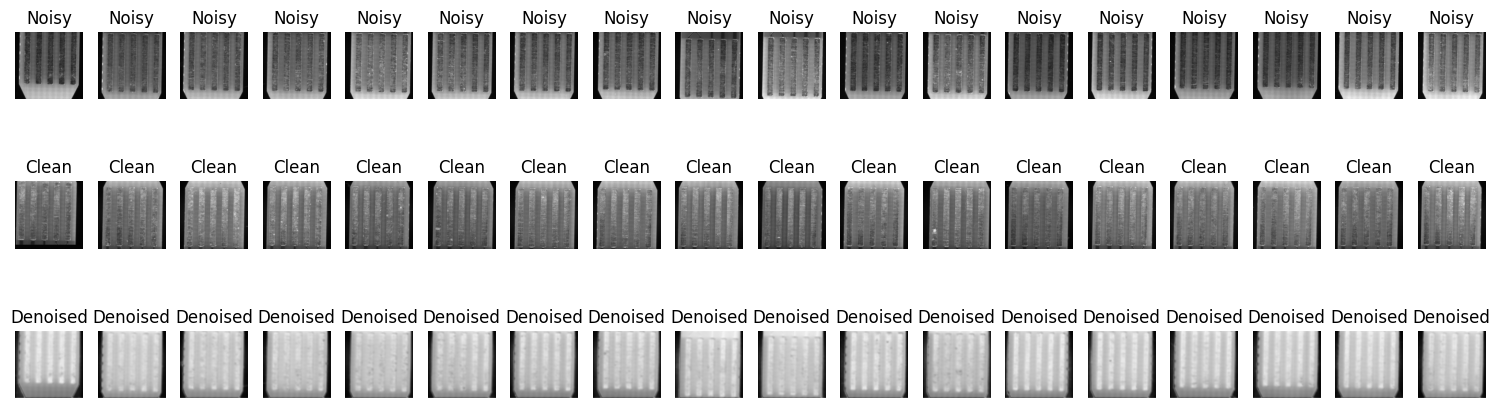

In [ ]:
import matplotlib.pyplot as plt

# Predict on the noisy input
denoised_images = autoencoder.predict(x_train_noisy)

# Display some example results
n = 18  # Number of image pairs to show
plt.figure(figsize=(15, 5))
for i in range(n):
    # Noisy input
    plt.subplot(3, n, i + 1)
    plt.imshow(x_train_noisy[i].squeeze(), cmap='gray')
    plt.title("Noisy")
    plt.axis('off')

    # Ground truth clean
    plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_train_clean[i].squeeze(), cmap='gray')
    plt.title("Clean")
    plt.axis('off')

    # Denoised output
    plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(denoised_images[i].squeeze(), cmap='gray')
    plt.title("Denoised")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import cv2

def sharpen_image(image):
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=1)
    sharpened = cv2.addWeighted(image, 1.5, blurred, -0.5, 0)
    return sharpened


In [ ]:
def combined_loss(y_true, y_pred):
    ssim = 1 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    edge_true = tf.image.sobel_edges(y_true)
    edge_pred = tf.image.sobel_edges(y_pred)
    edge_loss = tf.reduce_mean(tf.abs(edge_true - edge_pred))
    return ssim + 0.5 * edge_loss

Image 1: Mean Absolute Laplacian Difference = 0.0182
Image 2: Mean Absolute Laplacian Difference = 0.0189
Image 3: Mean Absolute Laplacian Difference = 0.0175
Image 4: Mean Absolute Laplacian Difference = 0.0190
Image 5: Mean Absolute Laplacian Difference = 0.0192


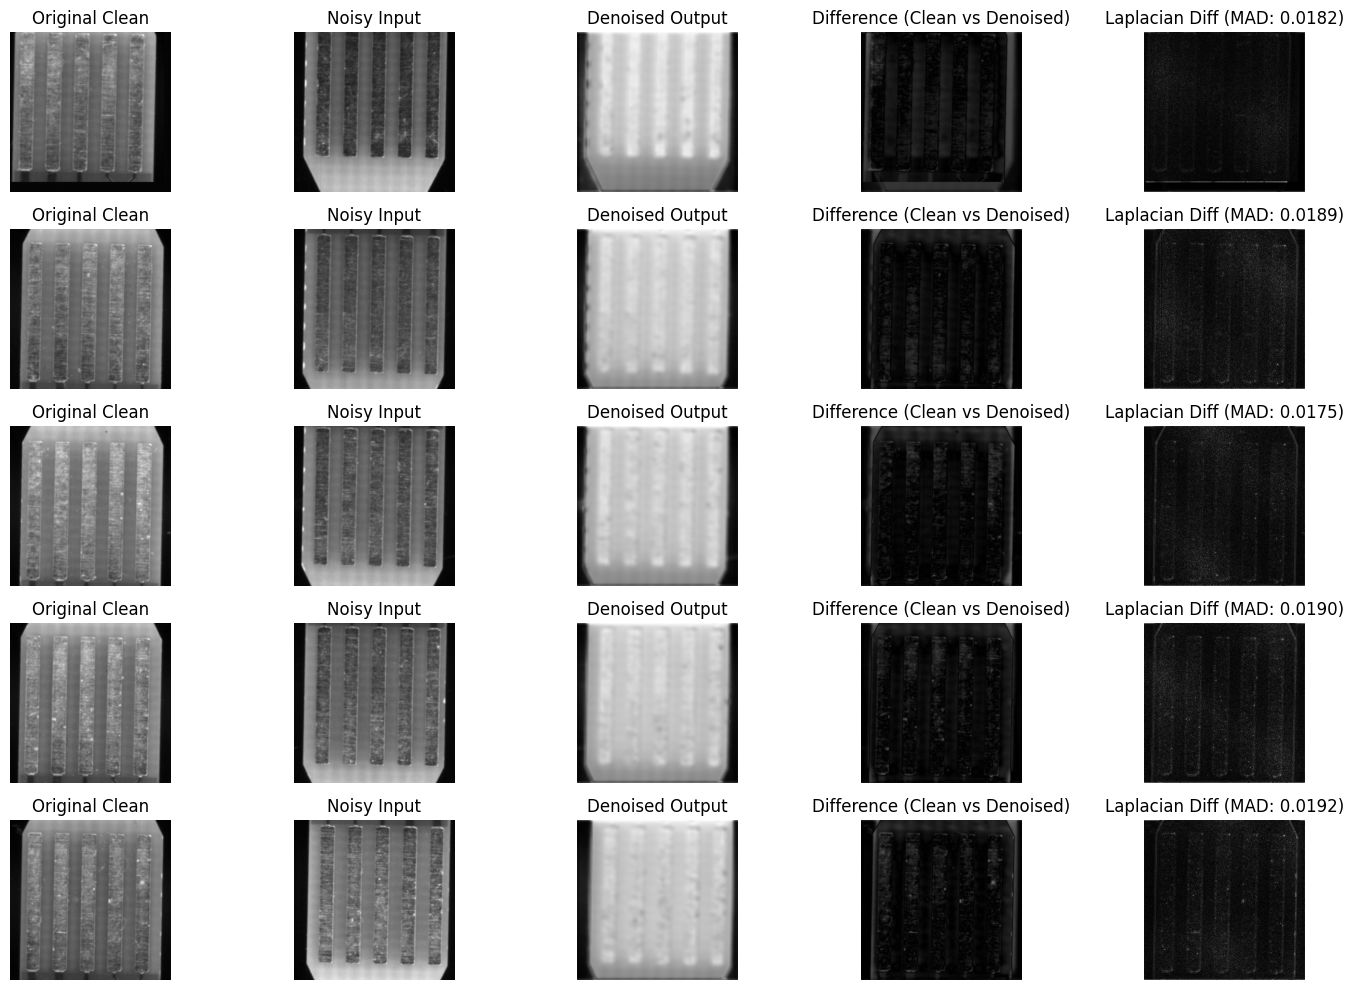

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2 # Import opencv

def calculate_laplacian_diff(original, denoised):
    # Ensure images are float for Laplacian calculation
    original_float = original.astype(np.float64)
    denoised_float = denoised.astype(np.float64)

    # Calculate the Laplacian of the original and denoised images using cv2.Laplacian
    # cv2.Laplacian requires a depth parameter. cv2.CV_64F is suitable for float64.
    laplacian_original = cv2.Laplacian(original_float, cv2.CV_64F)
    laplacian_denoised = cv2.Laplacian(denoised_float, cv2.CV_64F)

    # Calculate the absolute difference between the Laplacians
    laplacian_diff = np.abs(laplacian_original - laplacian_denoised)

    # Return the mean absolute difference as a metric
    return np.mean(laplacian_diff), laplacian_original, laplacian_denoised, laplacian_diff

# Calculate and visualize metrics for a few images
num_images_to_analyze = min(5, len(x_train_noisy)) # Analyze up to 5 images

plt.figure(figsize=(15, 10))

for i in range(num_images_to_analyze):
    original_image = x_train_clean[i].squeeze()
    denoised_image = denoised_images[i].squeeze()
    noisy_image = x_train_noisy[i].squeeze()

    # Calculate difference image
    difference_image = np.abs(original_image - denoised_image)

    # Calculate Laplacian difference metric and images
    mean_laplacian_diff, laplacian_original, laplacian_denoised, laplacian_diff_image = calculate_laplacian_diff(original_image, denoised_image)

    print(f"Image {i+1}: Mean Absolute Laplacian Difference = {mean_laplacian_diff:.4f}")

    # Plotting
    # Original Image
    plt.subplot(num_images_to_analyze, 5, i * 5 + 1)
    plt.imshow(original_image, cmap='gray')
    plt.title("Original Clean")
    plt.axis('off')

    # Noisy Image
    plt.subplot(num_images_to_analyze, 5, i * 5 + 2)
    plt.imshow(noisy_image, cmap='gray')
    plt.title("Noisy Input")
    plt.axis('off')

    # Denoised Image
    plt.subplot(num_images_to_analyze, 5, i * 5 + 3)
    plt.imshow(denoised_image, cmap='gray')
    plt.title("Denoised Output")
    plt.axis('off')

    # Difference Image (Original vs Denoised)
    plt.subplot(num_images_to_analyze, 5, i * 5 + 4)
    plt.imshow(difference_image, cmap='gray', vmin=0, vmax=1) # Assuming pixel values are scaled [0, 1]
    plt.title("Difference (Clean vs Denoised)")
    plt.axis('off')

    # Laplacian Difference Image
    plt.subplot(num_images_to_analyze, 5, i * 5 + 5)
    plt.imshow(laplacian_diff_image, cmap='gray') # Laplacian difference
    plt.title(f"Laplacian Diff (MAD: {mean_laplacian_diff:.4f})")
    plt.axis('off')


plt.tight_layout()
plt.show()

In [ ]:
!pip install keras_tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 2.5 MB/s eta 0:00:00


In [ ]:
import keras_tuner as kt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Cropping2D
import tensorflow as tf

def build_autoencoder(hp):
    input_img = Input(shape=(444, 446, 1))

    # Encoder
    x = Conv2D(
        filters=hp.Int('enc_conv1_filters', min_value=16, max_value=64, step=16),
        kernel_size=(3, 3),
        activation='relu',
        padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)

    x = Conv2D(
        filters=hp.Int('enc_conv2_filters', min_value=16, max_value=64, step=16),
        kernel_size=(3, 3),
        activation='relu',
        padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)

    # Decoder
    x = Conv2D(
        filters=hp.Int('dec_conv1_filters', min_value=16, max_value=64, step=16),
        kernel_size=(3, 3),
        activation='relu',
        padding='same')(x)
    x = UpSampling2D((2, 2))(x)

    x = Conv2D(
        filters=hp.Int('dec_conv2_filters', min_value=16, max_value=64, step=16),
        kernel_size=(3, 3),
        activation='relu',
        padding='same')(x)
    x = UpSampling2D((2, 2))(x)

    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    # Calculate cropping amounts
    output_h, output_w = tf.keras.backend.int_shape(decoded)[1:3]
    input_h, input_w = tf.keras.backend.int_shape(input_img)[1:3]

    crop_h_top = (output_h - input_h) // 2
    crop_h_bottom = output_h - input_h - crop_h_top
    crop_w_left = (output_w - input_w) // 2
    crop_w_right = output_w - input_w - crop_w_left

    cropped_decoded = Cropping2D(cropping=((crop_h_top, crop_h_bottom), (crop_w_left, crop_w_right)))(decoded)

    autoencoder = Model(input_img, cropped_decoded)
    autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
    return autoencoder

In [ ]:
import numpy as np

def extract_patches_from_rois(image, roi_list, patch_size=(32, 32)):
    """
    image: 2D numpy array (single denoised image)
    roi_list: list of tuples (x, y, w, h) for each ROI
    patch_size: size of patch to extract from each ROI
    Returns: list of patches as numpy arrays
    """
    patches = []
    for (x, y, w, h) in roi_list:
        roi = image[y:y+h, x:x+w]
        # Optionally, resize/crop ROI to patch_size
        if roi.shape[0] < patch_size[0] or roi.shape[1] < patch_size[1]:
            continue  # skip if ROI too small
        # Center crop to patch_size
        start_y = (roi.shape[0] - patch_size[0]) // 2
        start_x = (roi.shape[1] - patch_size[1]) // 2
        patch = roi[start_y:start_y+patch_size[0], start_x:start_x+patch_size[1]]
        patches.append(patch)
    return np.array(patches)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_patch_classifier(input_shape=(32, 32, 1)):
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

patch_classifier = build_patch_classifier(input_shape=(32,32,1))
patch_classifier.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 166,401 (650.00 KB)

 Trainable params: 166,401 (650.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Split into train/val if needed
from sklearn.model_selection import train_test_split

# Initialize all_patches and all_labels (Placeholder - Replace with your actual patch extraction and labeling)
all_patches = []
all_labels = []

# Assuming you have extracted patches into all_patches and assigned labels to all_labels
# For example:
# all_patches = np.array([...])  # your extracted patches
# all_labels = np.array([...])    # your corresponding labels (0 for good, 1 for bad)


# Check if there are enough samples to split
if len(all_patches) > 1 and len(all_labels) > 1 and len(all_patches) == len(all_labels):
    X_train, X_val, y_train, y_val = train_test_split(all_patches, all_labels, test_size=0.2, random_state=42)

    history = patch_classifier.fit(
        X_train, y_train,
        epochs=20,
        batch_size=32,
        validation_data=(X_val, y_val)
    )
else:
    print("Not enough data to perform train/validation split and training.")
    print(f"Number of patches: {len(all_patches)}, Number of labels: {len(all_labels)}")

Not enough data to perform train/validation split and training.
Number of patches: 0, Number of labels: 0


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
Prediction for example ROI: Detected = True, Confidence = 0.504891574382782


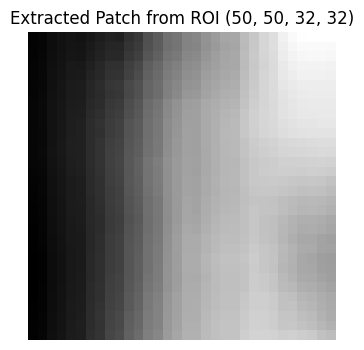

In [ ]:
def predict_line_in_roi(denoised_img, roi, model, patch_size=(32,32)):
    patches = extract_patches_from_rois(denoised_img.squeeze(), [roi], patch_size)
    if len(patches) == 0:
        return None, None
    patch = patches[0][np.newaxis, ..., np.newaxis]
    prob = model.predict(patch)[0][0]
    return prob > 0.5, prob


if 'denoised_images' in locals() and 'patch_classifier' in locals():

    example_roi = (50, 50, 32, 32) # Example: x=50, y=50, width=32, height=32

    # Extract the patch using the helper function
    patches_to_display = extract_patches_from_rois(denoised_images[0].squeeze(), [example_roi], patch_size=(32, 32))

    if len(patches_to_display) > 0:
        example_patch = patches_to_display[0]

        # Predict using the patch classifier (optional, but shows how to use the function)
        detected, confidence = predict_line_in_roi(denoised_images[0], example_roi, patch_classifier)

        print(f"Prediction for example ROI: Detected = {detected}, Confidence = {confidence}")

        # Display the extracted patch
        plt.figure(figsize=(4, 4))
        plt.imshow(example_patch.squeeze(), cmap='gray')
        plt.title(f"Extracted Patch from ROI {example_roi}")
        plt.axis('off')
        plt.show()
    else:
        print(f"No patch extracted for the example ROI {example_roi}. The ROI might be too small or outside the image boundaries after cropping.")
else:
    print("Please run the cells to generate 'denoised_images' and 'patch_classifier' first.")

In [ ]:
import numpy as np

def extract_patches(image, roi_list, patch_size=(64, 64)):
    """
    image: 2D numpy array (single denoised image)
    roi_list: list of tuples (x, y, w, h) for each ROI
    patch_size: output patch size (height, width)
    Returns: list of patches as numpy arrays
    """
    patches = []
    for (x, y, w, h) in roi_list:
        roi = image[y:y+h, x:x+w]
        # Center crop or resize ROI to patch_size
        if roi.shape[0] < patch_size[0] or roi.shape[1] < patch_size[1]:
            continue  # skip if ROI too small
        start_y = (roi.shape[0] - patch_size[0]) // 2
        start_x = (roi.shape[1] - patch_size[1]) // 2
        patch = roi[start_y:start_y+patch_size[0], start_x:start_x+patch_size[1]]
        patches.append(patch)
    return np.array(patches)[..., np.newaxis]  # add channel axis


In [ ]:
import numpy as np

# 1. Define dummy ROI labels for 18 images (replace with real ROIs as needed)
# Each image gets 2 ROIs: (x, y, w, h, label)
roi_labels = []
for i in range(18):
    # Example: two ROIs per image, one with a line (label=1), one without (label=0)
    rois = [
        (50, 50, 64, 64, 1),    # ROI 1: line present (dummy)
        (150, 150, 64, 64, 0)   # ROI 2: no line (dummy)
    ]
    roi_labels.append(rois)

# 2. Patch extraction function (same as before)
def extract_patches(image, roi_list, patch_size=(64, 64)):
    patches = []
    for (x, y, w, h) in roi_list:
        roi = image[y:y+h, x:x+w]
        # Center crop or resize ROI to patch_size
        if roi.shape[0] < patch_size[0] or roi.shape[1] < patch_size[1]:
            continue  # skip if ROI too small
        start_y = (roi.shape[0] - patch_size[0]) // 2
        start_x = (roi.shape[1] - patch_size[1]) // 2
        patch = roi[start_y:start_y+patch_size[0], start_x:start_x+patch_size[1]]
        patches.append(patch)
    return np.array(patches)[..., np.newaxis]  # add channel axis

# 3. Extract patches and labels for all denoised images
all_patches = []
all_labels = []
patch_size = (64, 64)

for img_idx, img in enumerate(denoised_images):
    roi_list = [ (x, y, w, h) for (x, y, w, h, label) in roi_labels[img_idx] ]
    labels = [ label for (x, y, w, h, label) in roi_labels[img_idx] ]
    patches = extract_patches(img.squeeze(), roi_list, patch_size)
    all_patches.extend(patches)
    all_labels.extend(labels)

all_patches = np.array(all_patches)
all_labels = np.array(all_labels)

print("Total patches:", all_patches.shape)
print("Total labels:", all_labels.shape)


Total patches: (36, 64, 64, 1)
Total labels: (36,)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_patch_classifier(input_shape=(64, 64, 1)):
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

patch_classifier = build_patch_classifier(input_shape=(64,64,1))
patch_classifier.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 821,761 (3.13 MB)

 Trainable params: 821,761 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(all_patches, all_labels, test_size=0.2, random_state=42)

history = patch_classifier.fit(
    X_train, y_train,
    epochs=15,
    batch_size=16,
    validation_data=(X_val, y_val)
)


Epoch 1/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 705ms/step - accuracy: 0.1399 - loss: 0.7537 - val_accuracy: 0.5000 - val_loss: 0.7137
Epoch 2/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 237ms/step - accuracy: 0.5000 - loss: 0.7083 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 3/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.4792 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 4/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 232ms/step - accuracy: 0.4583 - loss: 0.6942 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 5/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.5208 - loss: 0.6926 - val_accuracy: 0.5000 - val_loss: 0.6927
Epoch 6/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 448ms/step - accuracy: 0.5417 - loss: 0.6920 - val_accuracy: 0.5000 - val_loss: 0.6927
Epoch 7/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 422ms/step - accuracy: 0.5000 - loss: 0.6929 - val_accuracy: 0.5000 - val_loss: 0.6926
Epoch 8/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.4792 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss:

In [ ]:
def predict_line_in_roi(denoised_img, roi, model, patch_size=(64,64)):
    patch = extract_patches(denoised_img.squeeze(), [roi], patch_size)
    if len(patch) == 0:
        return None
    prob = model.predict(patch)[0][0]
    return prob > 0.5, prob

# Example usage:
# detected, confidence = predict_line_in_roi(denoised_images[0], (x, y, w, h), patch_classifier)
# print(f"Line detected: {detected}, Confidence: {confidence:.2f}")


In [ ]:
import matplotlib.pyplot as plt

def visualize_rois(image, roi_list, detected_list):
    plt.imshow(image.squeeze(), cmap='gray')
    for (x, y, w, h), detected in zip(roi_list, detected_list):
        color = 'g' if detected else 'r'
        rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, facecolor='none')
        plt.gca().add_patch(rect)
    plt.axis('off')
    plt.show()


In [ ]:
img_idx = 0  # Change this to visualize other images

# 1. Get the denoised image and its ROIs
denoised_img = denoised_images[img_idx]
roi_list = [ (x, y, w, h) for (x, y, w, h, label) in roi_labels[img_idx] ]

# 2. Predict line presence for each ROI
detected_list = []
for roi in roi_list:
    patch = extract_patches(denoised_img.squeeze(), [roi], patch_size)
    if len(patch) == 0:
        detected_list.append(False)
        continue
    prob = patch_classifier.predict(patch)[0][0]
    detected = prob > 0.5
    detected_list.append(detected)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 281ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


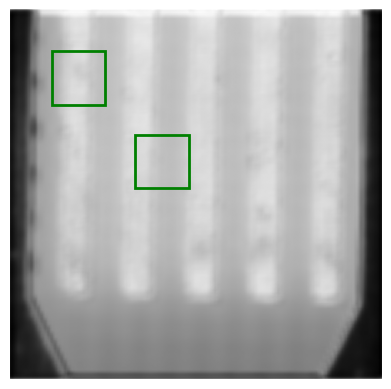

In [ ]:
visualize_rois(denoised_img, roi_list, detected_list)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step


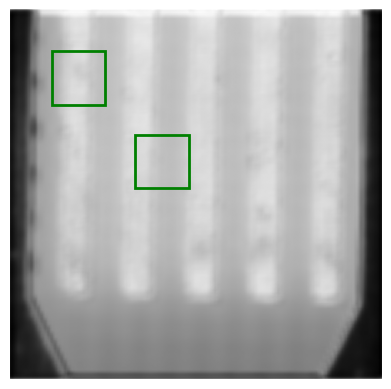

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


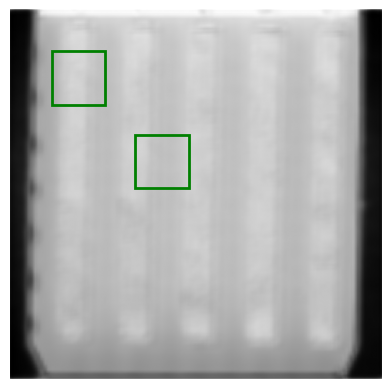

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


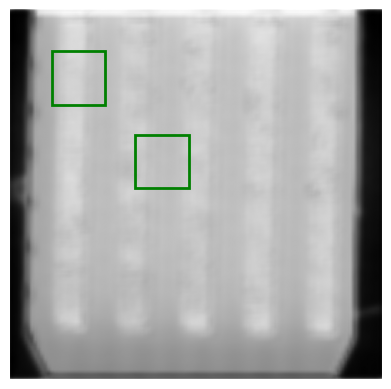

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


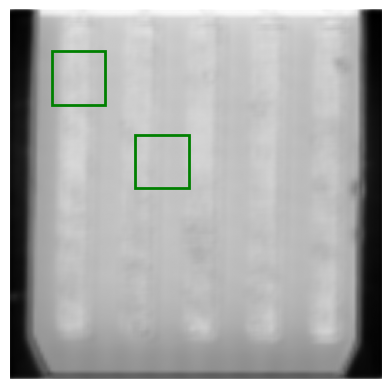

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


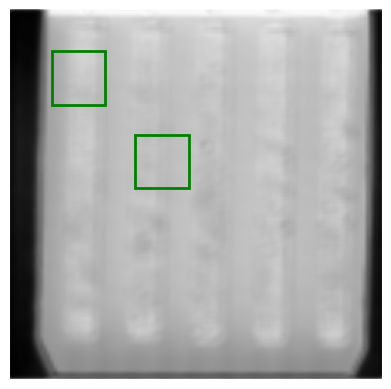

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


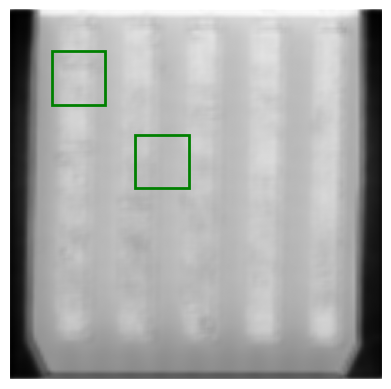

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


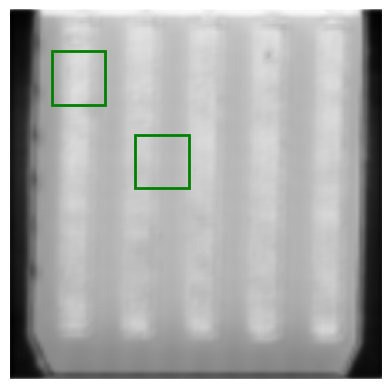

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


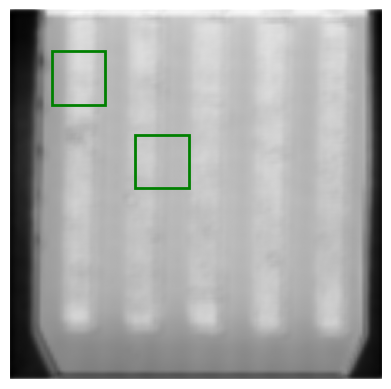

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


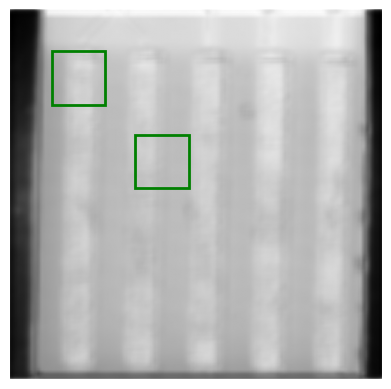

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


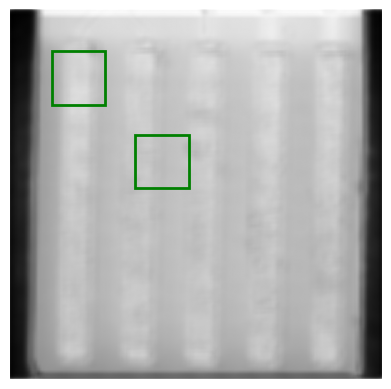

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


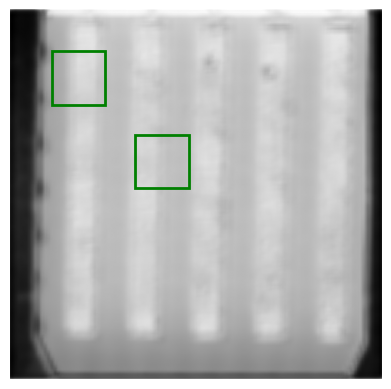

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


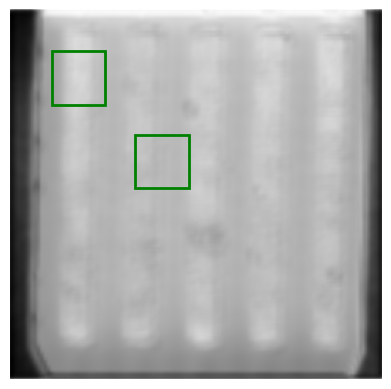

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


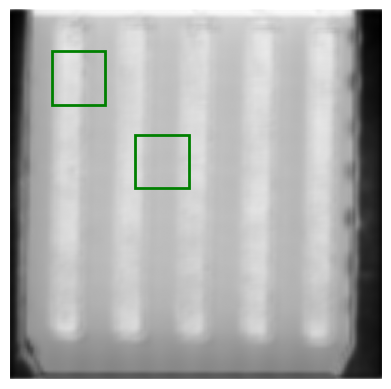

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


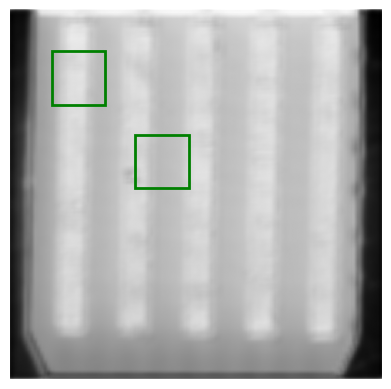

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


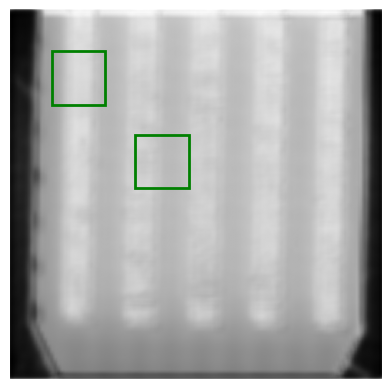

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


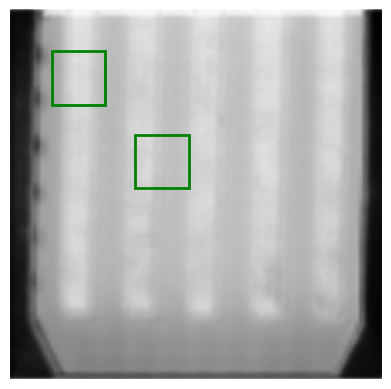

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


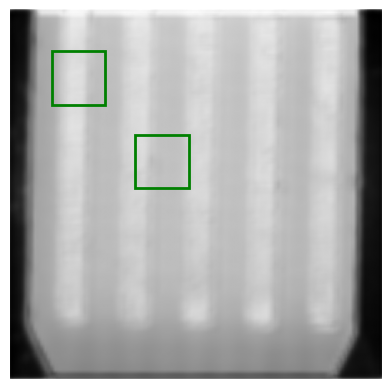

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


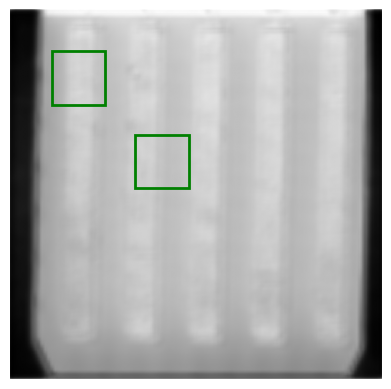

In [ ]:
for img_idx in range(len(denoised_images)):
    denoised_img = denoised_images[img_idx]
    roi_list = [ (x, y, w, h) for (x, y, w, h, label) in roi_labels[img_idx] ]
    detected_list = []
    for roi in roi_list:
        patch = extract_patches(denoised_img.squeeze(), [roi], patch_size)
        if len(patch) == 0:
            detected_list.append(False)
            continue
        prob = patch_classifier.predict(patch)[0][0]
        detected = prob > 0.5
        detected_list.append(detected)
    visualize_rois(denoised_img, roi_list, detected_list)
